# Person 4 · Autoencoder + Isolation Forest
**Project question.** Does isolation in a learned bottleneck detect attacks better than this autoencoder's reconstruction error and the team's PCA baseline?

The official score is `-IsolationForest.score_samples(Z)`, where `Z` is the raw output of the autoencoder's `latent` layer. The shared evaluator defines the official operating point at P99 of benign validation scores. Reconstruction MSE is an auxiliary comparison and supplies feature-level explanations.

## Executed result

The validation-only search selected **L32-W48**, **400 trees**
and **8,192 training embeddings per tree**. The locked benign P99 threshold was
`0.565601844454`. Over the shared test split the forest reached **0.8830 ROC-AUC**,
**0.6155 PR-AUC (average precision)**, **0.5625 F1** and
**6.121% false alarms**. The result tables below show the PCA target checks
and the comparison with reconstruction MSE.

In [1]:
import json
import os
import subprocess
import sys
from pathlib import Path

# Set before importing TensorFlow. CPU execution makes this run reproducible.
os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
os.environ["OMP_NUM_THREADS"] = "2"
os.environ["TF_NUM_INTRAOP_THREADS"] = "2"
os.environ["TF_NUM_INTEROP_THREADS"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import joblib
import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf
from IPython.display import display
from keras import layers
from sklearn.ensemble import IsolationForest

SEED = 42
REPO_URL = "https://github.com/JanaAlzobidi/iomt-anomaly-detection.git"
DATA_REVISION = "4994882e1b6e1bc337f8147556c9aa6d0cfcad21"
REPO = Path(os.environ.get("IOMT_REPO", "iomt-anomaly-detection")).resolve()
if not REPO.exists():
    subprocess.run(["git", "clone", REPO_URL, str(REPO)], check=True)
    subprocess.run(["git", "-C", str(REPO), "checkout", "--detach", DATA_REVISION], check=True)

sys.path.insert(0, str(REPO))
from evaluate import (compare_percentiles, evaluate, load_data, per_feature_errors,
                      reconstruction_errors, threshold_from_val)

DATA_DIR = REPO / "data"
RESULTS_DIR = REPO / "results"
MODEL_DIR = REPO / "models" / "ae_isoforest"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| scikit-learn", sklearn.__version__)
print("Repository revision:", subprocess.check_output(
    ["git", "-C", str(REPO), "rev-parse", "HEAD"], text=True
).strip())

TensorFlow 2.18.1 | Keras 3.15.1 | scikit-learn 1.8.0
Repository revision: 4994882e1b6e1bc337f8147556c9aa6d0cfcad21


## Use the project's prepared data

These are the original CICIoMT2024 WiFi and MQTT splits. The arrays already contain the team's preprocessing. The code preserves row membership, column order and values. Training and tuning use the benign training and validation splits. The test variables first enter scoring in the final evaluation section.

In [2]:
X_train, X_val, X_test, y_test, attack_test = load_data(str(DATA_DIR))
FEATURES = json.loads((DATA_DIR / "config.json").read_text(encoding="utf-8"))["features"]
INPUT_DIM = len(FEATURES)
assert X_train.shape == (150_000, INPUT_DIM)
assert X_val.shape == (30_000, INPUT_DIM)
assert INPUT_DIM == 40

PERCENTILE = 99.0
BATCH_SIZE = 1024
SCORE_BATCH_SIZE = 4096

X_train (150000, 40) (benign only) | X_val (30000, 40) (benign only) | X_test (42893, 40), attacks: 5286 (12.3%)


## Set the tuning rule using benign validation

Validation contains zero labeled attacks. Two artificial probes give the grid a selection signal. Packet-summary group swaps test whether the bottleneck picks up broken relationships between feature groups. Tail perturbations test sensitivity to unusual changes in continuous statistics. Both start from benign validation rows. Their detection rates are sensitivity checks and have no direct interpretation as recall on actual attacks.

For every candidate, compute its P99 threshold on all clean validation scores. Maximize the **lower** of the two probe detection rates at that threshold, followed by mean probe detection and benign validation MSE. This selects for both probe types at the shared operating point. The feature groups are defined by feature names and continuous perturbations are scaled using training IQRs. Input arrays remain unchanged.

In [3]:
rng = np.random.default_rng(SEED)
probe_rows = rng.choice(len(X_val), size=6_000, replace=False)
probe_base = X_val[probe_rows]
feature_index = {feature: i for i, feature in enumerate(FEATURES)}
feature_groups = [
    ["header_length", "duration", "rate", "iat"],
    ["fin_flag_number", "syn_flag_number", "rst_flag_number", "psh_flag_number",
     "ack_flag_number", "ece_flag_number", "cwr_flag_number", "ack_count",
     "syn_count", "fin_count", "rst_count"],
    ["protocol_type", "http", "https", "dns", "telnet", "ssh", "tcp",
     "udp", "dhcp", "arp", "icmp", "igmp", "ipv"],
    ["tot_sum", "min", "max", "avg", "std", "tot_size", "number",
     "magnitue", "radius", "covariance", "variance", "weight"],
]
group_swap = probe_base.copy()
group_choices = rng.integers(len(feature_groups), size=len(probe_base))
donor_rows = rng.integers(len(X_val), size=len(probe_base))
for group_number, group in enumerate(feature_groups):
    rows = np.flatnonzero(group_choices == group_number)
    columns = [feature_index[name] for name in group]
    group_swap[np.ix_(rows, columns)] = X_val[np.ix_(donor_rows[rows], columns)]
group_swap = group_swap[np.any(group_swap != probe_base, axis=1)]

q25, q75 = np.percentile(X_train, [25, 75], axis=0)
iqr = q75 - q25
continuous = np.array([feature_index[name] for name in feature_groups[0] + feature_groups[3]])
continuous = continuous[iqr[continuous] > 1e-4]
tail_shift = probe_base.copy()
perturbed_columns = rng.choice(continuous, size=len(probe_base))
shifts = rng.choice([-1, 1], len(probe_base)) * rng.uniform(0.8, 2.5, len(probe_base))
tail_shift[np.arange(len(probe_base)), perturbed_columns] += (
    shifts * iqr[perturbed_columns]
).astype(np.float32)
print("Probe rows:", {"group swap": len(group_swap), "tail shift": len(tail_shift)})

Probe rows: {'group swap': 5552, 'tail shift': 6000}


## Train regularized autoencoders

The grid covers bottlenecks of 8, 16 and 32 units and compares two L2 and dropout settings. MSE trains the decoder to reconstruct benign inputs. Early stopping restores the weights with lowest benign validation reconstruction MSE. The linear output can reconstruct values outside [0, 1].

In [4]:
AE_SETTINGS = [
    {"width": 48, "l2": 1e-6, "dropout": 0.0},
    {"width": 64, "l2": 1e-5, "dropout": 0.05},
]

def build_autoencoder(latent_size, width, l2, dropout):
    keras.utils.set_random_seed(SEED)
    penalty = keras.regularizers.L2(l2)
    inputs = keras.Input(shape=(INPUT_DIM,), name="packet_features")
    hidden = layers.Dense(width, activation="relu", kernel_regularizer=penalty)(inputs)
    hidden = layers.Dropout(dropout, seed=SEED)(hidden)
    latent = layers.Dense(latent_size, name="latent", kernel_regularizer=penalty)(hidden)
    hidden = layers.Dense(width, activation="relu", kernel_regularizer=penalty)(latent)
    output = layers.Dense(INPUT_DIM, activation="linear", name="reconstruction")(hidden)
    model = keras.Model(inputs, output, name="person4_autoencoder")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss="mse", metrics=["mse"])
    return model

def make_encoder(model):
    return keras.Model(model.inputs, model.get_layer("latent").output)

def encode(encoder, rows):
    return encoder.predict(rows, batch_size=SCORE_BATCH_SIZE, verbose=0)

def fit_autoencoder(model):
    # Prefetch batches while bounding the CPU thread pool.
    options = tf.data.Options()
    options.threading.private_threadpool_size = 2
    train = tf.data.Dataset.from_tensor_slices((X_train, X_train))
    train = train.shuffle(len(X_train), seed=SEED).batch(BATCH_SIZE)
    clean_validation = tf.data.Dataset.from_tensor_slices((X_val, X_val)).batch(BATCH_SIZE)
    stop = keras.callbacks.EarlyStopping(
        monitor="val_mse", patience=4, min_delta=0.0, restore_best_weights=True
    )
    return model.fit(
        train.with_options(options).prefetch(1),
        validation_data=clean_validation.with_options(options).prefetch(1),
        epochs=35, callbacks=[stop], verbose=0,
    ).history

trained = {}
for latent_size in (8, 16, 32):
    for settings in AE_SETTINGS:
        name = f"L{latent_size}-W{settings['width']}"
        model = build_autoencoder(latent_size, **settings)
        history = fit_autoencoder(model)
        trained[name] = (model, history)
        print(f"{name}: {len(history['val_mse'])} epochs, "
              f"best validation MSE {min(history['val_mse']):.6g}", flush=True)

L8-W48: 35 epochs, best validation MSE 0.00041656
L8-W64: 35 epochs, best validation MSE 0.00035847
L16-W48: 35 epochs, best validation MSE 9.31609e-05
L16-W64: 35 epochs, best validation MSE 0.000203315
L32-W48: 35 epochs, best validation MSE 3.6872e-05
L32-W64: 35 epochs, best validation MSE 0.000195279


/home/agent/.local/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


## Train Isolation Forest and lock the model

Each forest is fit on benign training embeddings from the named `latent` layer. The grid varies the number of trees and training rows sampled per tree. Each candidate uses the same seed and percentile. The forest selected below is the exact forest used for final evaluation.

In [5]:
def negative_isolation_score(forest, embeddings):
    # scikit-learn assigns smaller scores to more isolated rows.
    return -forest.score_samples(embeddings)

records = []
best_key = None
best_forest = None
for name, (model, history) in trained.items():
    encoder = make_encoder(model)
    z_train = encode(encoder, X_train)
    z_val = encode(encoder, X_val)
    z_swap = encode(encoder, group_swap)
    z_tail = encode(encoder, tail_shift)
    probe_embeddings = np.concatenate([z_swap, z_tail])
    for max_samples in (256, 2048, 8192):
        for n_estimators in (200, 400):
            forest = IsolationForest(
                n_estimators=n_estimators, max_samples=max_samples,
                random_state=SEED, n_jobs=4,
            ).fit(z_train)
            clean_scores = negative_isolation_score(forest, z_val)
            threshold = threshold_from_val(clean_scores, PERCENTILE)
            probe_scores = negative_isolation_score(forest, probe_embeddings)
            swap_rate = np.mean(probe_scores[:len(z_swap)] > threshold)
            tail_rate = np.mean(probe_scores[len(z_swap):] > threshold)
            records.append({
                "AE": name, "max_samples": max_samples, "trees": n_estimators,
                "group_swap_detection": swap_rate, "tail_shift_detection": tail_rate,
                "min_probe_detection": min(swap_rate, tail_rate),
                "mean_probe_detection": (swap_rate + tail_rate) / 2,
                "val_mse": min(history["val_mse"]),
            })
            sort_key = (-min(swap_rate, tail_rate), -(swap_rate + tail_rate) / 2,
                        min(history["val_mse"]), n_estimators, max_samples, name)
            if best_key is None or sort_key < best_key:
                best_key, best_forest = sort_key, forest
    print("Completed forest grid for", name, flush=True)

tuning = pd.DataFrame(records).sort_values(
    ["min_probe_detection", "mean_probe_detection", "val_mse", "trees", "max_samples", "AE"],
    ascending=[False, False, True, True, True, True],
).reset_index(drop=True)
selected = tuning.iloc[0]
autoencoder, history = trained[selected["AE"]]
encoder = make_encoder(autoencoder)
iso = best_forest
display(tuning.head(10).round(5))
del trained, best_forest

def iso_scores(rows, fitted_encoder=encoder, fitted_forest=iso):
    return negative_isolation_score(fitted_forest, encode(fitted_encoder, rows))

val_scores = iso_scores(X_val)
locked_threshold = threshold_from_val(val_scores, PERCENTILE)
print(f"Locked P{PERCENTILE:g} threshold: {locked_threshold:.12g}")

Completed forest grid for L8-W48
Completed forest grid for L8-W64
Completed forest grid for L16-W48
Completed forest grid for L16-W64
Completed forest grid for L32-W48
Completed forest grid for L32-W64
Locked P99 threshold: 0.565601844454


,AE,max_samples,trees,group_swap_detection,tail_shift_detection,min_probe_detection,mean_probe_detection,val_mse
0,L32-W48,8192,400,0.04935,0.04767,0.04767,0.04851,0.00004
1,L16-W48,8192,200,0.04719,0.04733,0.04719,0.04726,0.00009
2,L32-W48,8192,200,0.04863,0.04700,0.04700,0.04782,0.00004
3,L16-W48,8192,400,0.04773,0.04650,0.04650,0.04712,0.00009
4,L8-W48,8192,400,0.04827,0.04533,0.04533,0.04680,0.00042
5,L8-W48,8192,200,0.04773,0.04533,0.04533,0.04653,0.00042
6,L8-W64,8192,200,0.04323,0.03683,0.03683,0.04003,0.00036
7,L8-W64,8192,400,0.04161,0.03550,0.03550,0.03855,0.00036
8,L32-W64,8192,400,0.03728,0.03400,0.03400,0.03564,0.00020
9,L32-W64,8192,200,0.03692,0.03333,0.03333,0.03513,0.00020


The learning curves show how benign reconstruction MSE changed for the selected autoencoder. The forest's model selection uses the probe table above.

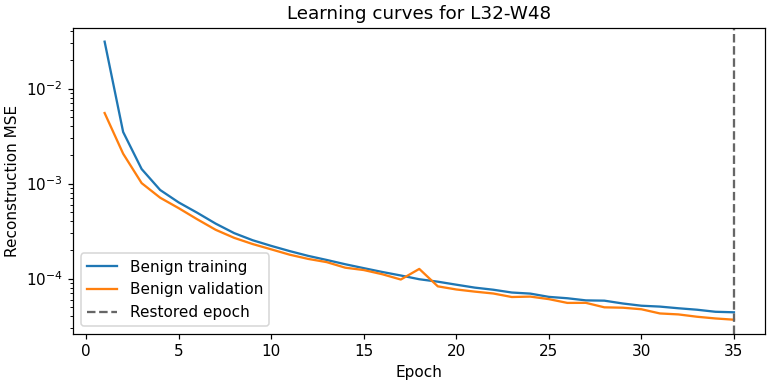

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
epochs = range(1, len(history["mse"]) + 1)
ax.plot(epochs, history["mse"], label="Benign training")
ax.plot(epochs, history["val_mse"], label="Benign validation")
ax.axvline(np.argmin(history["val_mse"]) + 1, color="0.4", linestyle="--",
           label="Restored epoch")
ax.set(xlabel="Epoch", ylabel="Reconstruction MSE", yscale="log",
       title=f"Learning curves for {selected['AE']}")
ax.legend()
plt.show()

## Run the shared final evaluation

The comparison uses `evaluate` for both score types. The official Person 4 result is written by the project evaluator. The same autoencoder's MSE is evaluated at its own benign-validation P99 to answer the project's comparison question. The percentile table is diagnostic. The official threshold remains the one locked above.


===== AE + Isolation Forest =====
Threshold (P99 of validation scores): 0.565602
          roc_auc: 0.8830
           pr_auc: 0.6155
               f1: 0.5625
        precision: 0.5633
           recall: 0.5617
 false_alarm_rate: 0.0612

Confusion matrix (rows = true, cols = predicted)
        Benign  Attack
Benign   35305    2302
Attack    2317    2969

Recall per attack type (weakest first):
                           n recall
type                               
ARP Spoofing             300  0.000
MQTT DoS Publish Flood   300  0.000
MQTT DoS Connect Flood   300  0.000
MQTT DDoS Connect Flood  300  0.000
MQTT DDoS Publish Flood  300  0.010
MQTT Malformed Data      300  0.047
Recon VulScan            300  0.173
Recon PingSweep          186  0.645
Recon OSScan             300  0.710
Recon PortScan           300  0.757
DoS SYN Flood            300  0.880
DoS TCP Flood            300  0.967
DoS ICMP Flood           300  0.973
DDoS SYN Flood           300  0.993
DDoS TCP Flood           3

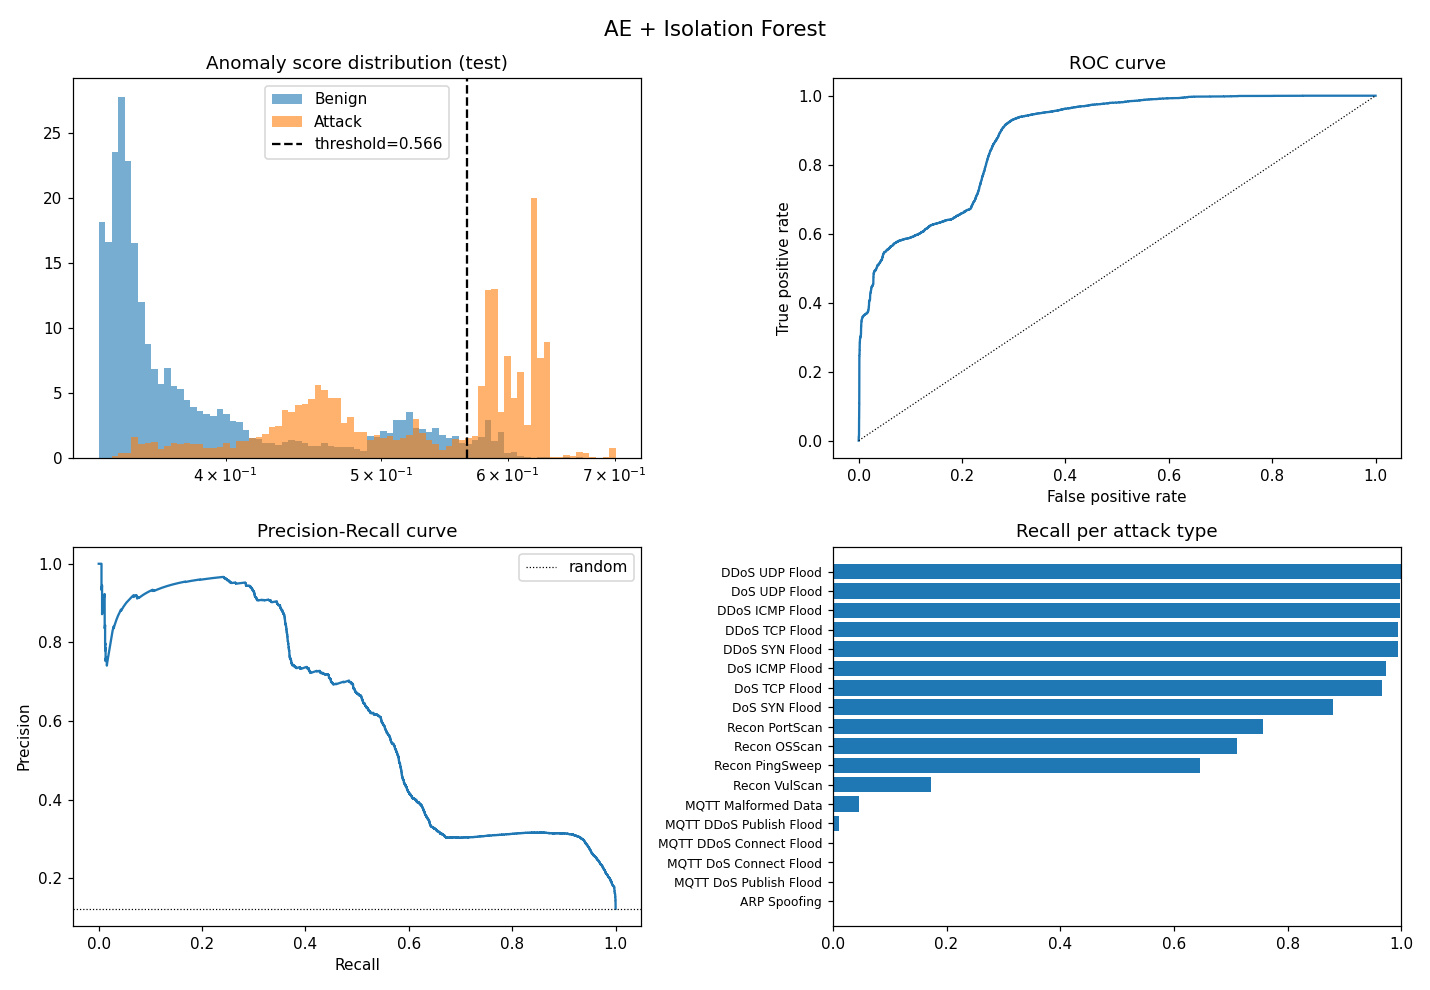

In [7]:
test_scores = iso_scores(X_test)
res = evaluate(
    test_scores, y_test, attack_test, val_scores,
    model_name="AE + Isolation Forest", person="4",
    percentile=PERCENTILE, save_dir=str(RESULTS_DIR),
)
assert res["threshold"] == locked_threshold
threshold_sensitivity = compare_percentiles(test_scores, y_test, val_scores)

mse_res = evaluate(
    reconstruction_errors(autoencoder, X_test), y_test, attack_test,
    reconstruction_errors(autoencoder, X_val),
    model_name="Person 4 AE reconstruction comparison", person="4",
    percentile=PERCENTILE, plot=False,
)

## Compare PCA targets and difficult traffic types

PR-AUC here is the evaluator's average precision. False alarm rate is the share of benign test rows flagged, so smaller values are better. For hard attacks, compare the current results against the PDF's rounded PCA figures. ARP, MQTT, PingSweep and VulScan show how performance varies beyond flooding traffic.

In [8]:
targets = {
    "roc_auc": 0.938, "pr_auc": 0.835, "f1": 0.761, "false_alarm_rate": 0.0037,
}
metrics = pd.DataFrame({
    "PCA target": targets,
    "Person 4 latent + forest": {metric: res[metric] for metric in targets},
    "Same AE reconstruction": {metric: mse_res[metric] for metric in targets},
})
metrics["Target beaten"] = [
    res[metric] < goal if metric == "false_alarm_rate" else res[metric] > goal
    for metric, goal in targets.items()
]
display(metrics.round(6))

def pca_reported_recall(attack):
    name = attack.lower()
    if "arp" in name:
        return "~1%"
    if "mqtt" in name:
        return "4–29% (MQTT range)"
    return "~40%"

hard_attacks = [
    attack for attack in res["per_attack_recall"]
    if any(token in attack.lower() for token in ("arp", "mqtt", "pingsweep", "vulscan"))
]
hard = pd.DataFrame({
    "PCA (PDF)": {name: pca_reported_recall(name) for name in hard_attacks},
    "Latent + forest recall": {name: res["per_attack_recall"][name] for name in hard_attacks},
    "AE reconstruction recall": {name: mse_res["per_attack_recall"][name] for name in hard_attacks},
})
display(hard)

,PCA target,Person 4 latent + forest,Same AE reconstruction,Target beaten
roc_auc,0.9380,0.883033,0.955934,False
pr_auc,0.8350,0.615531,0.906159,False
f1,0.7610,0.562470,0.888186,False
false_alarm_rate,0.0037,0.061212,0.008961,False


,PCA (PDF),Latent + forest recall,AE reconstruction recall
ARP Spoofing,~1%,0.0000,0.0367
MQTT DoS Publish Flood,4–29% (MQTT range),0.0000,1.0000
MQTT DoS Connect Flood,4–29% (MQTT range),0.0000,1.0000
MQTT DDoS Connect Flood,4–29% (MQTT range),0.0000,1.0000
MQTT DDoS Publish Flood,4–29% (MQTT range),0.0100,1.0000
MQTT Malformed Data,4–29% (MQTT range),0.0467,0.2367
Recon VulScan,~40%,0.1733,0.4667
Recon PingSweep,~40%,0.6452,0.6022


## Interpretation

At their respective benign P99 thresholds, reconstruction MSE led the latent forest in
ROC-AUC (0.9559 vs 0.8830), average precision (0.9062 vs 0.6155), and F1
(0.8882 vs 0.5625). The latent forest flagged 2,302 of 37,607 benign test rows (6.12%).
The reconstruction comparison also exceeded the 0.37% false-alarm target, at 0.90%.

The latent forest detected 64.5% of Recon PingSweep, above the PCA notebook's
37.6%. It detected 17.3% of Recon VulScan versus PCA's 40.3%. It flagged no ARP
Spoofing rows and detected 0% to 4.7% across the five MQTT variants. The four
MQTT flood types each reached 100% recall under reconstruction MSE, and
MQTT Malformed Data reached 23.7%. The synthetic tuning probes capture only
selected deviations from benign data, so their rankings can differ from the real
attack results.

## Save, reload and predict

The two saved models and metadata are the Person 4 handoff. The metadata records the exact evaluator threshold, feature order, selection and package versions. Use trusted model files and matching scikit-learn versions when loading. `predict(X)` accepts prepared 40-column rows in the project's feature order. Its three feature names identify the largest squared reconstruction errors, which describe unusual measurements in the row. They are a reconstruction-based explanation of the row. The decision itself uses the forest score.

In [9]:
AE_PATH = MODEL_DIR / "ae_isoforest.keras"
FOREST_PATH = MODEL_DIR / "isolation_forest.pkl"
METADATA_PATH = MODEL_DIR / "inference_metadata.json"

autoencoder.save(AE_PATH)
joblib.dump(iso, FOREST_PATH, compress=3)
metadata = {
    "threshold": res["threshold"], "percentile": PERCENTILE, "features": FEATURES,
    "selected_configuration": {
        "autoencoder": selected["AE"], "max_samples": int(selected["max_samples"]),
        "n_estimators": int(selected["trees"]),
    },
    "versions": {"tensorflow": tf.__version__, "keras": keras.__version__,
                 "scikit-learn": sklearn.__version__, "numpy": np.__version__,
                 "joblib": joblib.__version__},
    "data_revision": DATA_REVISION,
}
METADATA_PATH.write_text(json.dumps(metadata, indent=2) + "\n", encoding="utf-8")
tuning.to_csv(MODEL_DIR / "validation_tuning.csv", index=False)

loaded_autoencoder = keras.models.load_model(AE_PATH, compile=False)
loaded_encoder = make_encoder(loaded_autoencoder)
loaded_forest = joblib.load(FOREST_PATH)
loaded_metadata = json.loads(METADATA_PATH.read_text(encoding="utf-8"))
THRESHOLD = loaded_metadata["threshold"]
feature_names = np.asarray(loaded_metadata["features"])
assert THRESHOLD == res["threshold"]

reloaded_scores = iso_scores(X_test, loaded_encoder, loaded_forest)
np.testing.assert_array_equal(reloaded_scores, test_scores)
np.testing.assert_array_equal(
    iso_scores(X_val, loaded_encoder, loaded_forest), val_scores
)
np.testing.assert_array_equal(
    reconstruction_errors(loaded_autoencoder, X_test),
    reconstruction_errors(autoencoder, X_test),
)
print(f"Reload verified on all {len(X_val):,} validation and {len(X_test):,} test rows.")

Reload verified on all 30,000 validation and 42,893 test rows.


In [10]:
def predict(X):
    rows = np.asarray(X, dtype=np.float32)
    if rows.ndim == 1:
        rows = rows.reshape(1, -1)
    if rows.ndim != 2 or rows.shape[1] != len(feature_names):
        raise ValueError(f"Expected prepared rows with {len(feature_names)} features.")
    if not np.isfinite(rows).all():
        raise ValueError("Prepared features must be finite.")
    if len(rows) == 0:
        return []

    scores = iso_scores(rows, loaded_encoder, loaded_forest)
    errors = per_feature_errors(loaded_autoencoder, rows)
    top_indices = np.argsort(-errors, axis=1, kind="stable")[:, :3]
    return [
        {"score": float(score), "is_anomaly": bool(score > THRESHOLD),
         "top_features": feature_names[indices].tolist()}
        for score, indices in zip(scores, top_indices)
    ]

examples = predict(X_test[:5])
np.testing.assert_array_equal([item["score"] for item in examples], test_scores[:5])
display(pd.DataFrame(examples))

,score,is_anomaly,top_features
0,0.345102,False,"[max, avg, syn_count]"
1,0.586410,True,"[ack_flag_number, tcp, udp]"
2,0.389751,False,"[covariance, max, magnitue]"
3,0.469809,False,"[number, iat, syn_flag_number]"
4,0.342188,False,"[covariance, syn_flag_number, rate]"


Evaluation on the shared test split is a benchmark comparison. Earlier project notebooks also used this split. The team should use the cross-model comparison to decide whether this candidate gets the Gradio interface in the final handoff.